In [1]:
import pandas as pd
from pathlib import Path
import joblib

ROOT = Path.cwd().parent
TRAIN_DIR = ROOT / "data" / "processed" / "train_test"

X_train = pd.read_csv(TRAIN_DIR / "X_train.csv")
X_test = pd.read_csv(TRAIN_DIR / "X_test.csv")

y_train = pd.read_csv(TRAIN_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(TRAIN_DIR / "y_test.csv").squeeze()

scaler = joblib.load(TRAIN_DIR / "scaler.pkl")

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train:", X_train_scaled.shape)
print("X_test :", X_test_scaled.shape)

X_train: (556, 9)
X_test : (140, 9)


In [2]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("✅ Logistic Regression trained.")

✅ Logistic Regression trained.


In [3]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Predictions:", y_pred[:10])
print("Probabilities:", y_prob[:10])

Predictions: [0 0 1 0 0 1 0 0 1 0]
Probabilities: [1.81877502e-01 1.74760877e-04 9.99017560e-01 2.11210946e-01
 1.28555957e-01 7.42574212e-01 1.00459941e-01 3.49233818e-01
 9.97105975e-01 1.68173447e-01]


In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Results")
print("-" * 35)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Logistic Regression Results
-----------------------------------
Accuracy : 0.8929
Precision: 0.9508
Recall   : 0.8286
F1 Score : 0.8855
ROC-AUC  : 0.9578


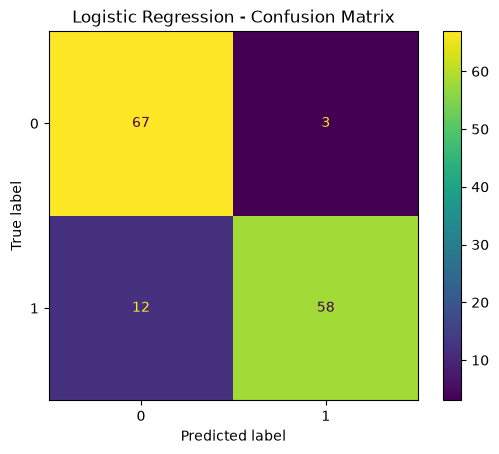

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [6]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Genuine", "Fake"]
    )
)

              precision    recall  f1-score   support

     Genuine       0.85      0.96      0.90        70
        Fake       0.95      0.83      0.89        70

    accuracy                           0.89       140
   macro avg       0.90      0.89      0.89       140
weighted avg       0.90      0.89      0.89       140



In [7]:
FEATURES = [
    "followers",
    "following",
    "posts",
    "bio_length",
    "has_profile_picture",
    "is_private",
    "username_digit_ratio",
    "follower_following_ratio",
    "profile_completeness"
]

coefficients = pd.DataFrame({
    "feature": FEATURES,
    "coefficient": model.coef_[0]
})

coefficients["absolute_coefficient"] = (
    coefficients["coefficient"].abs()
)

coefficients.sort_values(
    "absolute_coefficient",
    ascending=False
)

,feature,coefficient,absolute_coefficient
2,posts,-2.564632,2.564632
4,has_profile_picture,-2.024030,2.024030
6,username_digit_ratio,1.660180,1.660180
3,bio_length,-0.771753,0.771753
0,followers,-0.339677,0.339677
1,following,0.185182,0.185182
5,is_private,-0.152141,0.152141
7,follower_following_ratio,-0.024242,0.024242
8,profile_completeness,0.000000,0.000000


In [8]:
MODEL_DIR = ROOT / "backend" / "trained_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model,
    MODEL_DIR / "logistic_regression.pkl"
)

print("✅ Model saved.")

✅ Model saved.
